# Multimodal Pedestrian-Flow Prediction: Model Development and Internal Validation

This analysis develops separate predictive models for peak pedestrian flow along the road and across the road. Its purpose is to compare a prespecified set of model families under a common validation protocol and to identify provisional models for subsequent pipeline implementation. All non-null candidate models use both contextual and imagery-derived predictors.

## 1. Analysis Objectives and Prespecified Decisions

The primary objective is prediction at an unobserved road site. The two outcomes are `obs_peak_along_ped_per_h` and `obs_peak_cross_ped_per_h`, both expressed as pedestrians per hour. Mean absolute error (MAE) on the original pedestrians-per-hour scale is the primary selection metric because it has a direct operational interpretation. Root mean squared error (RMSE) and out-of-fold R² are secondary metrics. Model comparison, hyperparameter tuning, preprocessing, and embedded feature selection are performed within grouped spatial cross-validation.

The null model is an intercept-only model that predicts the training-fold mean. It quantifies the performance available without any predictor information. A candidate model is useful only when it improves materially on this null model and remains stable across validation repeats.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.cluster import DBSCAN
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Ridge, TweedieRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.metrics.pairwise import haversine_distances
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_PATH = Path('../../data/processed/model_dataset.xlsx')
SEED = 20260918
OUTER_FOLDS = 5
INNER_FOLDS = 3
OUTER_REPEATS = 3
SPATIAL_LINK_KM = 1.0

TARGETS = ['obs_peak_along_ped_per_h', 'obs_peak_cross_ped_per_h']
TARGET_LABELS = {
    'obs_peak_along_ped_per_h': 'Along-road pedestrian flow',
    'obs_peak_cross_ped_per_h': 'Cross-road pedestrian flow',
}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


## 2. Data and Outcome Audit

The opposite pedestrian-flow outcome is never used to predict the other outcome. The following checks verify record uniqueness, target validity, and coordinate validity before modelling.

,Outcome,count,mean,std,min,25%,50%,75%,max,Zero observations
0,obs_peak_along_ped_per_h,49.0,39.87,70.53,0.67,8.33,13.00,35.33,349.67,0
1,obs_peak_cross_ped_per_h,49.0,25.39,38.81,0.00,3.00,7.33,32.33,192.33,1


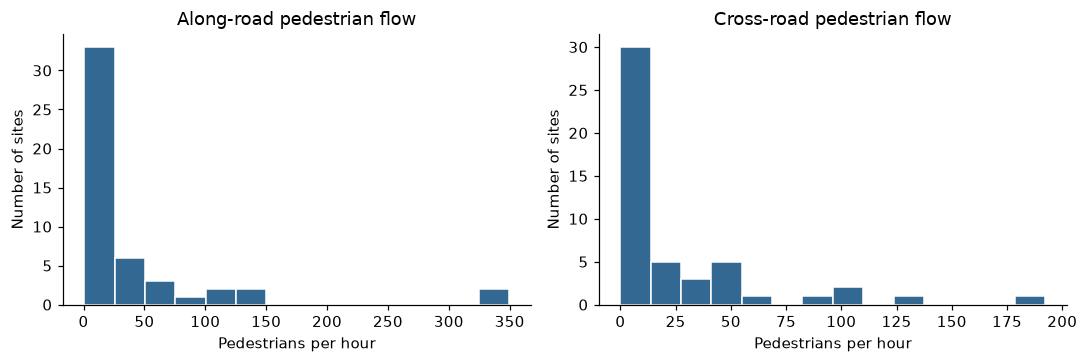

In [2]:
data = pd.read_excel(DATA_PATH, sheet_name='Model_Data').sort_values('site_id').reset_index(drop=True)

required = ['site_id', 'latitude', 'longitude', *TARGETS]
assert set(required).issubset(data.columns)
assert data['site_id'].notna().all() and data['site_id'].is_unique
assert np.isfinite(data[TARGETS + ['latitude', 'longitude']].to_numpy(float)).all()
assert data[TARGETS].ge(0).all().all()
assert data['latitude'].between(-90, 90).all()
assert data['longitude'].between(-180, 180).all()

outcome_summary = data[TARGETS].describe().T.rename_axis('Outcome').reset_index()
outcome_summary['Zero observations'] = [(data[target] == 0).sum() for target in TARGETS]
display(outcome_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for axis, target in zip(axes, TARGETS):
    axis.hist(data[target], bins=14, color='#326891', edgecolor='white')
    axis.set(title=TARGET_LABELS[target], xlabel='Pedestrians per hour', ylabel='Number of sites')
plt.tight_layout()
plt.show()


## 3. Predictor Eligibility and Multimodal Feature Specification

Predictor eligibility is determined before examining model performance. The candidate pool begins with 24 contextual variables and 13 imagery-derived variables. Two contextual variables are removed because, within a fixed 500 m buffer, they are deterministic rescalings of retained building variables. Two footpath flags are deferred because their definitions are unresolved and 10 sites are positive for both. Four imagery indicators are deferred because the smaller binary group contains fewer than five sites, which does not support a stable contrast in this sample. Five observations is a pragmatic minimum-support rule rather than a universal statistical threshold.

All remaining non-null models receive the same eligible multimodal predictor pool: 22 contextual variables and 7 imagery variables. No model is labelled "context only" or "imagery only." Rare levels of retained categorical variables are pooled by the encoder when fewer than five training-fold observations support a level. This operation occurs inside each training fold. Differences in effective feature count arise from model regularisation, particularly Elastic Net, rather than from arbitrary feature-count bands.

In [3]:
CONTEXT_FEATURES = [
    'abs_mb_category_2021', 'abs_mb_area_sqkm_2021', 'abs_mb_dwellings_2021',
    'abs_mb_persons_usual_resident_2021', 'abs_mb_dwellings_per_sqkm_2021',
    'abs_mb_persons_per_sqkm_2021', 'pta_nearest_active_stop_distance_m',
    'pta_nearest_active_stop_type', 'pta_active_stops_within_500m',
    'health_nearest_establishment_distance_m', 'health_nearest_establishment_category',
    'health_nearest_establishment_type', 'education_nearest_active_school_distance_m',
    'education_nearest_school_sector', 'education_nearest_school_low_year',
    'education_nearest_school_high_year', 'ms_building_count_500m',
    'ms_building_footprint_area_m2_500m', 'overture_food_drink_count_500m',
    'overture_grocery_convenience_pharmacy_count_500m',
    'overture_shopping_mall_present_500m', 'overture_other_shopping_count_500m',
]
IMAGERY_FEATURES = [
    'pedestrian_crossings', 'commercial_buildings', 'residential_buildings',
    'industrial_buildings', 'parking_areas', 'park_bushland_reserve',
    'shared_pedestrian_and_cycle_path',
]
EXCLUDED_FEATURES = {
    'ms_building_count_per_sqkm_500m': 'Deterministic rescaling of building count in a fixed buffer',
    'ms_building_coverage_ratio_500m': 'Deterministic rescaling of footprint area in a fixed buffer',
    'footpath_both_sides': 'Definition unresolved; overlaps with footpath_one_side',
    'footpath_one_side': 'Definition unresolved; overlaps with footpath_both_sides',
    'fencing_barriers': 'Minority group has 3 sites',
    'railway_station': 'Minority group has 2 sites',
    'bus_stops': 'Minority group has 2 sites',
    'overpass_bridge': 'Minority group has 1 site',
}
CATEGORICAL_FEATURES = [
    'abs_mb_category_2021', 'pta_nearest_active_stop_type',
    'health_nearest_establishment_category', 'health_nearest_establishment_type',
    'education_nearest_school_sector', 'education_nearest_school_low_year',
    'education_nearest_school_high_year',
]
ELIGIBLE_FEATURES = CONTEXT_FEATURES + IMAGERY_FEATURES

assert set(ELIGIBLE_FEATURES + list(EXCLUDED_FEATURES)).issubset(data.columns)
assert not set(ELIGIBLE_FEATURES) & set(TARGETS + ['site_id', 'latitude', 'longitude'])

feature_audit = pd.DataFrame([
    *[{'Source': 'Context', 'Feature': feature, 'Decision': 'Include',
       'Basis': 'Eligible contextual predictor'} for feature in CONTEXT_FEATURES],
    *[{'Source': 'Imagery', 'Feature': feature, 'Decision': 'Include',
       'Basis': 'Eligible imagery predictor; provenance still requires validation'} for feature in IMAGERY_FEATURES],
    *[{'Source': 'Context' if feature.startswith('ms_') else 'Imagery',
       'Feature': feature, 'Decision': 'Defer', 'Basis': reason}
      for feature, reason in EXCLUDED_FEATURES.items()],
])
display(feature_audit.groupby(['Source', 'Decision']).size().rename('Number of raw features').to_frame())
display(feature_audit[feature_audit['Decision'] == 'Defer'])

X = data[ELIGIBLE_FEATURES].copy()
land_use = X['abs_mb_category_2021']
X['abs_mb_category_2021'] = land_use.where(
    land_use.isin(['Residential', 'Commercial']), 'Other'
)
X.loc[land_use.isna(), 'abs_mb_category_2021'] = np.nan

for feature in ELIGIBLE_FEATURES:
    if feature in CATEGORICAL_FEATURES:
        X[feature] = X[feature].map(lambda value: str(value) if pd.notna(value) else np.nan)
    else:
        X[feature] = pd.to_numeric(X[feature], errors='raise').astype(float)
        assert X[feature].dropna().ge(0).all()

print(f'Eligible multimodal pool: {len(CONTEXT_FEATURES)} context + '
      f'{len(IMAGERY_FEATURES)} imagery = {len(ELIGIBLE_FEATURES)} raw predictors')


Number of raw features
Source  Decision                        
Context Defer                          2
        Include                       22
Imagery Defer                          6
        Include                        7

,Source,Feature,Decision,Basis
29,Context,ms_building_count_per_sqkm_500m,Defer,Deterministic rescaling of building count in a...
30,Context,ms_building_coverage_ratio_500m,Defer,Deterministic rescaling of footprint area in a...
31,Imagery,footpath_both_sides,Defer,Definition unresolved; overlaps with footpath_...
32,Imagery,footpath_one_side,Defer,Definition unresolved; overlaps with footpath_...
33,Imagery,fencing_barriers,Defer,Minority group has 3 sites
34,Imagery,railway_station,Defer,Minority group has 2 sites
35,Imagery,bus_stops,Defer,Minority group has 2 sites
36,Imagery,overpass_bridge,Defer,Minority group has 1 site


Eligible multimodal pool: 22 context + 7 imagery = 29 raw predictors


## 4. Internal-Validation Design

A single train/test split would evaluate each model on approximately ten sites and would be highly sensitive to which sites were selected. This analysis therefore uses three repeats of five-fold outer cross-validation. Sites separated by 1 km or less are connected into the same spatial group, preventing overlapping 500 m contextual buffers from being assigned to training and validation in the same fold. The inner three-fold grouped cross-validation selects hyperparameters and, for Elastic Net, the degree of coefficient sparsity.

Every site receives one out-of-fold prediction in each repeat. Reported standard deviations describe variation across the three prespecified repeat partitions; they are not confidence intervals. The 1 km linkage rule addresses local buffer overlap but does not establish generalisation to an entirely new town or region.

In [4]:
EARTH_RADIUS_KM = 6371.0088


def spatial_groups(frame, link_km=SPATIAL_LINK_KM):
    coordinates = np.radians(frame[['latitude', 'longitude']].to_numpy(float))
    return DBSCAN(
        eps=link_km / EARTH_RADIUS_KM,
        min_samples=1,
        metric='haversine',
    ).fit_predict(coordinates)


def balanced_group_splits(groups, n_splits, seed):
    groups = np.asarray(groups)
    unique_groups, group_sizes = np.unique(groups, return_counts=True)
    n_splits = min(n_splits, len(unique_groups))
    if n_splits < 2:
        raise ValueError('At least two independent spatial groups are required.')

    rng = np.random.default_rng(seed)
    order = rng.permutation(len(unique_groups))
    order = order[np.argsort(-group_sizes[order], kind='stable')]
    fold_sizes = np.zeros(n_splits, dtype=int)
    assignment = {}
    for position in order:
        available = np.flatnonzero(fold_sizes == fold_sizes.min())
        fold = int(rng.choice(available))
        assignment[unique_groups[position]] = fold
        fold_sizes[fold] += group_sizes[position]

    fold_label = np.array([assignment[group] for group in groups])
    splits = []
    for fold in range(n_splits):
        train = np.flatnonzero(fold_label != fold)
        test = np.flatnonzero(fold_label == fold)
        assert set(groups[train]).isdisjoint(groups[test])
        splits.append((train, test))
    return splits


groups = spatial_groups(data)
distance_matrix = haversine_distances(
    np.radians(data[['latitude', 'longitude']].to_numpy(float))
) * EARTH_RADIUS_KM

split_audit = []
for repeat in range(OUTER_REPEATS):
    splits = balanced_group_splits(groups, OUTER_FOLDS, SEED + repeat)
    for fold, (train, test) in enumerate(splits, start=1):
        minimum_distance = distance_matrix[np.ix_(train, test)].min()
        assert minimum_distance > SPATIAL_LINK_KM - 1e-8
        split_audit.append({
            'Repeat': repeat + 1,
            'Fold': fold,
            'Training sites': len(train),
            'Validation sites': len(test),
            'Minimum train-validation distance (km)': minimum_distance,
        })

print(f'{len(data)} sites form {len(np.unique(groups))} spatial groups.')
display(pd.DataFrame(split_audit).round(3))


49 sites form 45 spatial groups.


,Repeat,Fold,Training sites,Validation sites,Minimum train-validation distance (km)
0,1,1,39,10,16.383
1,1,2,39,10,3.375
2,1,3,39,10,1.330
3,1,4,40,9,13.466
4,1,5,39,10,1.330
5,2,1,40,9,1.330
6,2,2,39,10,3.375
7,2,3,39,10,16.383
8,2,4,39,10,20.016
9,2,5,39,10,1.330


## 5. Candidate Models

The candidate set is deliberately limited to models that address a distinct modelling question. The null model provides the no-information reference. Ridge tests a linear model with shrinkage under correlated predictors. Elastic Net adds embedded feature selection; its raw-outcome and log1p-outcome variants are evaluated separately. The Tweedie model provides a log-link regression for a non-negative, right-skewed outcome that may include zero. A constrained random forest provides a non-linear benchmark. Unregularised multivariable OLS is not used because one-hot encoding yields a high parameter count relative to 49 sites and the predictors are correlated.

| Model | Role | Feature Treatment |
|---|---|---|
| Null model | Intercept-only training mean | No predictors |
| Ridge | Regularised linear relation | All eligible context + imagery |
| Elastic Net | Linear shrinkage and embedded selection | All eligible context + imagery |
| Elastic Net (log1p outcome) | Multiplicative-scale linear relation | All eligible context + imagery |
| Tweedie GLM | Non-negative skewed-response regression | All eligible context + imagery |
| Random Forest | Constrained non-linear benchmark | All eligible context + imagery |

In [5]:
NUMERIC_FEATURES = [feature for feature in ELIGIBLE_FEATURES if feature not in CATEGORICAL_FEATURES]


def preprocessing_pipeline():
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scale', StandardScaler()),
    ])
    categorical = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
        ('encode', OneHotEncoder(
            handle_unknown='infrequent_if_exist',
            min_frequency=5,
            sparse_output=False,
        )),
    ])
    return ColumnTransformer([
        ('numeric', numeric, NUMERIC_FEATURES),
        ('categorical', categorical, CATEGORICAL_FEATURES),
    ], remainder='drop', verbose_feature_names_out=True)


def regression_candidate(name, estimator, parameter_grid, log_target=False):
    pipeline = Pipeline([
        ('preprocess', preprocessing_pipeline()),
        ('remove_constant', VarianceThreshold()),
        ('model', estimator),
    ])
    model = TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p if log_target else None,
        inverse_func=np.expm1 if log_target else None,
        check_inverse=True,
    )
    grid = {f'regressor__model__{parameter}': values
            for parameter, values in parameter_grid.items()}
    return {'name': name, 'estimator': model, 'grid': grid}


CANDIDATES = [
    {'name': 'Null model', 'estimator': DummyRegressor(strategy='mean'), 'grid': {}},
    regression_candidate('Ridge', Ridge(), {'alpha': [0.1, 1.0, 10.0, 100.0]}),
    regression_candidate(
        'Elastic Net', ElasticNet(max_iter=50000, tol=1e-4),
        {'alpha': [0.03, 0.1, 0.3, 1.0, 3.0, 10.0], 'l1_ratio': [0.2, 0.5, 0.8]},
    ),
    regression_candidate(
        'Elastic Net (log1p outcome)', ElasticNet(max_iter=50000, tol=1e-4),
        {'alpha': [0.03, 0.1, 0.3, 1.0, 3.0, 10.0], 'l1_ratio': [0.2, 0.5, 0.8]},
        log_target=True,
    ),
    regression_candidate(
        'Tweedie GLM', TweedieRegressor(power=1.5, link='log', max_iter=10000),
        {'alpha': [0.1, 1.0, 10.0, 100.0]},
    ),
    regression_candidate(
        'Random forest',
        RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1),
        {'max_depth': [2, 4], 'min_samples_leaf': [5, 10], 'max_features': [0.7, 1.0]},
    ),
]

display(pd.DataFrame({
    'Candidate model': [candidate['name'] for candidate in CANDIDATES],
    'Uses context predictors': [False] + [True] * (len(CANDIDATES) - 1),
    'Uses imagery predictors': [False] + [True] * (len(CANDIDATES) - 1),
}))


,Candidate model,Uses context predictors,Uses imagery predictors
0,Null model,False,False
1,Ridge,True,True
2,Elastic Net,True,True
3,Elastic Net (log1p outcome),True,True
4,Tweedie GLM,True,True
5,Random forest,True,True


## 6. Nested Spatial Cross-Validation

Each fixed candidate model is evaluated on every outer validation fold. In parallel, a "model-selection procedure" is evaluated: within each outer training set, the inner validation score selects one candidate family and its hyperparameters, after which that fitted candidate predicts the outer validation fold. This row estimates the performance of the full selection procedure rather than the performance of a single fixed model. Negative predictions are mapped to zero because both outcomes are non-negative; positive predictions are not capped.

In [6]:
def nonnegative(prediction):
    prediction = np.asarray(prediction, dtype=float)
    if not np.isfinite(prediction).all():
        raise ValueError('A candidate produced non-finite predictions.')
    return np.maximum(prediction, 0.0)


def clipped_mae(y_true, y_predicted):
    return mean_absolute_error(y_true, nonnegative(y_predicted))


MAE_SCORER = make_scorer(clipped_mae, greater_is_better=False)


def raw_feature_name(encoded_name):
    if encoded_name.startswith('numeric__'):
        return encoded_name.removeprefix('numeric__')
    label = encoded_name.removeprefix('categorical__')
    for feature in CATEGORICAL_FEATURES:
        if label == feature or label.startswith(feature + '_'):
            return feature
    return label


def elastic_net_selections(fitted_model, target, candidate, repeat, fold):
    if not candidate.startswith('Elastic Net'):
        return []
    pipeline = fitted_model.regressor_
    encoded_names = pipeline.named_steps['preprocess'].get_feature_names_out()
    keep = pipeline.named_steps['remove_constant'].get_support()
    selected_names = encoded_names[keep][np.abs(pipeline.named_steps['model'].coef_) > 1e-8]
    selected_raw = set(map(raw_feature_name, selected_names))
    return [{
        'Target': target,
        'Candidate': candidate,
        'Repeat': repeat,
        'Fold': fold,
        'Raw feature': feature,
        'Selected': feature in selected_raw,
    } for feature in ELIGIBLE_FEATURES]


def fit_candidate(candidate, X_train, y_train, inner_splits):
    search = GridSearchCV(
        estimator=clone(candidate['estimator']),
        param_grid=candidate['grid'],
        scoring=MAE_SCORER,
        cv=inner_splits,
        refit=True,
        n_jobs=1,
        error_score='raise',
    )
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        search.fit(X_train, y_train)
    return search


predictions = []
fold_results = []
selection_records = []

for target in TARGETS:
    y = data[target].to_numpy(float)
    for repeat in range(OUTER_REPEATS):
        outer_splits = balanced_group_splits(groups, OUTER_FOLDS, SEED + repeat)
        for fold, (train, test) in enumerate(outer_splits, start=1):
            inner_splits = balanced_group_splits(
                groups[train], INNER_FOLDS, SEED + 1000 + repeat * 100 + fold
            )
            fitted_candidates = []
            for candidate in CANDIDATES:
                search = fit_candidate(candidate, X.iloc[train], y[train], inner_splits)
                predicted = nonnegative(search.predict(X.iloc[test]))
                model_name = candidate['name']
                fold_results.append({
                    'Target': target,
                    'Candidate': model_name,
                    'Repeat': repeat + 1,
                    'Fold': fold,
                    'Inner MAE': -search.best_score_,
                    'Parameters': str(search.best_params_),
                })
                selection_records.extend(elastic_net_selections(
                    search.best_estimator_, target, model_name, repeat + 1, fold
                ))
                fitted_candidates.append((float(-search.best_score_), model_name, predicted))
                for row_index, prediction in zip(test, predicted):
                    predictions.append({
                        'Target': target,
                        'Candidate': model_name,
                        'Repeat': repeat + 1,
                        'Fold': fold,
                        'Site': data.iloc[row_index]['site_id'],
                        'Observed': y[row_index],
                        'Predicted': float(prediction),
                        'Training maximum': float(y[train].max()),
                    })

            selected = min(fitted_candidates, key=lambda item: item[0])
            fold_results.append({
                'Target': target,
                'Candidate': 'Model-selection procedure',
                'Repeat': repeat + 1,
                'Fold': fold,
                'Inner MAE': selected[0],
                'Parameters': f'Selected candidate: {selected[1]}',
            })
            for row_index, prediction in zip(test, selected[2]):
                predictions.append({
                    'Target': target,
                    'Candidate': 'Model-selection procedure',
                    'Repeat': repeat + 1,
                    'Fold': fold,
                    'Site': data.iloc[row_index]['site_id'],
                    'Observed': y[row_index],
                    'Predicted': float(prediction),
                    'Training maximum': float(y[train].max()),
                })

        print(f'Completed {TARGET_LABELS[target]} — repeat {repeat + 1}/{OUTER_REPEATS}', flush=True)

predictions = pd.DataFrame(predictions)
fold_results = pd.DataFrame(fold_results)
selection_records = pd.DataFrame(selection_records)

assert not predictions.duplicated(['Target', 'Candidate', 'Repeat', 'Site']).any()
assert predictions.groupby(['Target', 'Candidate', 'Repeat']).size().eq(len(data)).all()


Completed Along-road pedestrian flow — repeat 1/3
Completed Along-road pedestrian flow — repeat 2/3
Completed Along-road pedestrian flow — repeat 3/3
Completed Cross-road pedestrian flow — repeat 1/3
Completed Cross-road pedestrian flow — repeat 2/3
Completed Cross-road pedestrian flow — repeat 3/3


## 7. Model Performance Comparison

Performance is calculated from the complete set of out-of-fold predictions within each repeat and then summarised across repeats. "MAE improvement versus null" is the percentage reduction in MAE relative to the intercept-only null model for the same outcome. Ranking is based on mean MAE. The model-selection procedure is reported separately because it is an adaptive workflow rather than a fixed model family.

In [7]:
repeat_performance = []
for (target, candidate, repeat), part in predictions.groupby(['Target', 'Candidate', 'Repeat']):
    repeat_performance.append({
        'Target': target,
        'Candidate': candidate,
        'Repeat': repeat,
        'MAE': mean_absolute_error(part['Observed'], part['Predicted']),
        'RMSE': np.sqrt(mean_squared_error(part['Observed'], part['Predicted'])),
        'R²': r2_score(part['Observed'], part['Predicted']),
    })
repeat_performance = pd.DataFrame(repeat_performance)

performance = repeat_performance.groupby(['Target', 'Candidate']).agg(
    MAE=('MAE', 'mean'),
    MAE_SD=('MAE', 'std'),
    RMSE=('RMSE', 'mean'),
    RMSE_SD=('RMSE', 'std'),
    R2=('R²', 'mean'),
).reset_index()

null_mae = performance[performance['Candidate'] == 'Null model'].set_index('Target')['MAE']
performance['MAE improvement vs null (%)'] = [
    100 * (1 - row.MAE / null_mae[row.Target]) for row in performance.itertuples()
]
performance['MAE rank'] = performance.groupby('Target')['MAE'].rank(method='min').astype(int)
performance = performance.sort_values(['Target', 'MAE'])

for target in TARGETS:
    print(TARGET_LABELS[target])
    display(
        performance[performance['Target'] == target]
        .drop(columns='Target')
        .round(3)
        .reset_index(drop=True)
    )

print('Model family selected within each outer training set:')
selection_frequency = (
    fold_results[fold_results['Candidate'] == 'Model-selection procedure']
    .assign(Selected=lambda frame: frame['Parameters'].str.replace('Selected candidate: ', '', regex=False))
    .groupby(['Target', 'Selected']).size().rename('Number of outer folds').reset_index()
)
display(selection_frequency)


Along-road pedestrian flow


,Candidate,MAE,MAE_SD,RMSE,RMSE_SD,R2,MAE improvement vs null (%),MAE rank
0,Model-selection procedure,26.674,1.851,57.885,9.458,0.300,37.819,1
1,Elastic Net (log1p outcome),26.747,1.921,58.220,9.431,0.292,37.649,2
2,Tweedie GLM,31.295,1.724,65.124,3.832,0.128,27.048,3
3,Random forest,31.438,2.187,61.720,3.656,0.216,26.715,4
4,Elastic Net,32.059,1.139,61.227,2.495,0.230,25.266,5
5,Ridge,32.852,0.767,62.406,1.988,0.200,23.419,6
6,Null model,42.898,0.749,72.146,0.362,-0.068,0.000,7


Cross-road pedestrian flow


,Candidate,MAE,MAE_SD,RMSE,RMSE_SD,R2,MAE improvement vs null (%),MAE rank
0,Model-selection procedure,19.991,1.738,36.390,4.305,0.094,28.028,1
1,Elastic Net (log1p outcome),20.221,1.177,38.224,4.070,0.002,27.198,2
2,Random forest,21.013,0.397,34.812,0.929,0.178,24.346,3
3,Elastic Net,21.555,1.008,34.618,0.525,0.188,22.396,4
4,Ridge,22.055,1.206,35.048,1.809,0.166,20.596,5
5,Tweedie GLM,23.950,4.214,46.423,17.604,-0.601,13.773,6
6,Null model,27.776,0.357,39.512,0.486,-0.058,0.000,7


Model family selected within each outer training set:


,Target,Selected,Number of outer folds
0,obs_peak_along_ped_per_h,Elastic Net (log1p outcome),14
1,obs_peak_along_ped_per_h,Tweedie GLM,1
2,obs_peak_cross_ped_per_h,Elastic Net,1
3,obs_peak_cross_ped_per_h,Elastic Net (log1p outcome),11
4,obs_peak_cross_ped_per_h,Random forest,2
5,obs_peak_cross_ped_per_h,Tweedie GLM,1


## 8. Out-of-Fold Prediction Diagnostics

For each outcome, the diagnostic plots use the fixed candidate with the lowest mean MAE, excluding the adaptive selection-procedure row. Each point is the mean of the three out-of-fold predictions for one site and is shown only for visual diagnosis; the formal performance table is calculated separately within each repeat. The residual table identifies the five sites with the largest mean absolute prediction errors. Predictions greater than three times the maximum outcome observed in the corresponding training fold are reported as an extrapolation diagnostic and are not automatically removed or capped.

,Target,Lowest-MAE fixed candidate
0,obs_peak_along_ped_per_h,Elastic Net (log1p outcome)
1,obs_peak_cross_ped_per_h,Elastic Net (log1p outcome)


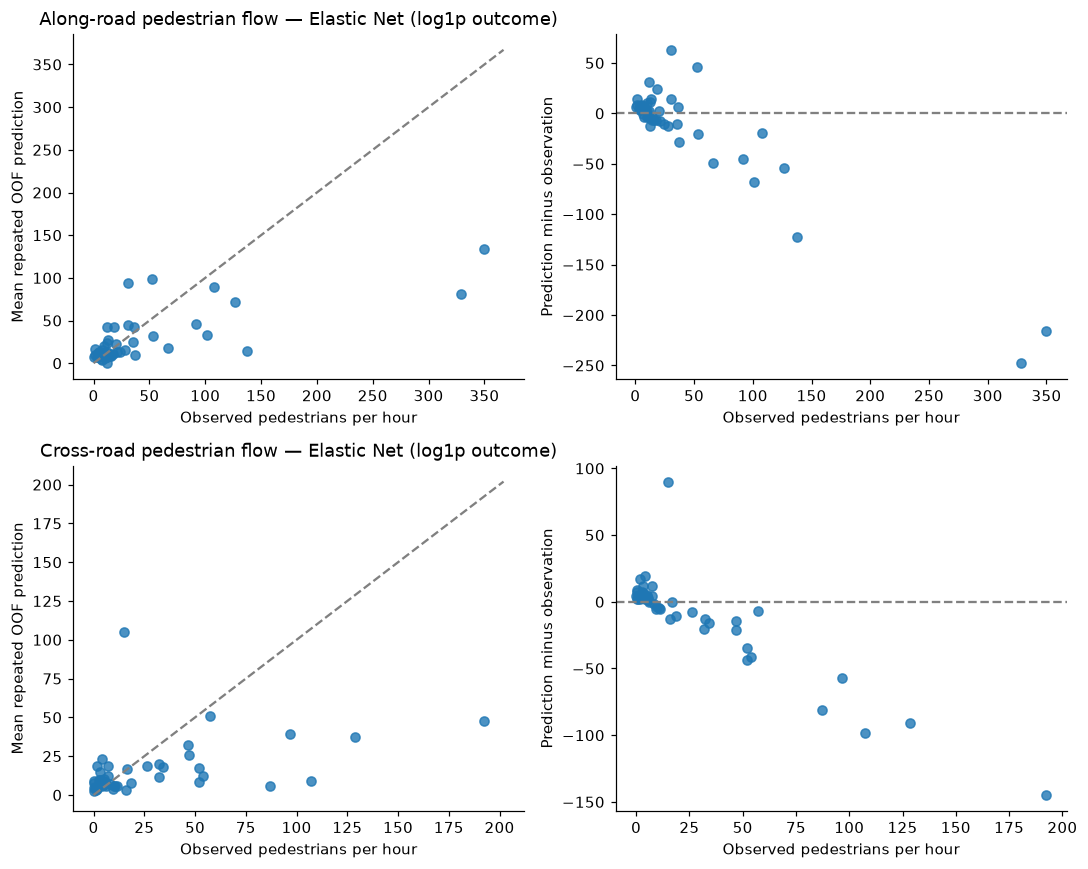

,Site,Observed,Predicted,Error,Absolute error,Target,Candidate
10,250303-11,328.67,80.87,-247.79,247.79,obs_peak_along_ped_per_h,Elastic Net (log1p outcome)
9,250303-10,349.67,133.90,-215.77,215.77,obs_peak_along_ped_per_h,Elastic Net (log1p outcome)
59,250303-11,192.33,47.54,-144.79,144.79,obs_peak_cross_ped_per_h,Elastic Net (log1p outcome)
29,260335-33,137.33,14.89,-122.44,122.44,obs_peak_along_ped_per_h,Elastic Net (log1p outcome)
78,260335-33,107.33,9.09,-98.24,98.24,obs_peak_cross_ped_per_h,Elastic Net (log1p outcome)
80,260335-35,128.67,37.54,-91.13,91.13,obs_peak_cross_ped_per_h,Elastic Net (log1p outcome)
64,250303-16,15.00,105.09,90.09,90.09,obs_peak_cross_ped_per_h,Elastic Net (log1p outcome)
69,250341-04,87.00,5.67,-81.33,81.33,obs_peak_cross_ped_per_h,Elastic Net (log1p outcome)
2,250303-03,101.33,32.97,-68.37,68.37,obs_peak_along_ped_per_h,Elastic Net (log1p outcome)
15,250303-16,30.67,93.66,63.00,63.00,obs_peak_along_ped_per_h,Elastic Net (log1p outcome)


Predictions above three times the training-fold maximum: 0


,Target,Candidate,Repeat,Fold,Site,Observed,Predicted,Training maximum


In [8]:
fixed_performance = performance[performance['Candidate'] != 'Model-selection procedure']
best_fixed = (
    fixed_performance.sort_values(['Target', 'MAE'])
    .groupby('Target', as_index=False).first()[['Target', 'Candidate']]
)
display(best_fixed.rename(columns={'Candidate': 'Lowest-MAE fixed candidate'}))

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
diagnostic_rows = []
for row, target in enumerate(TARGETS):
    candidate = best_fixed.loc[best_fixed['Target'] == target, 'Candidate'].iloc[0]
    part = predictions[(predictions['Target'] == target) & (predictions['Candidate'] == candidate)]
    site_predictions = part.groupby('Site').agg(
        Observed=('Observed', 'first'),
        Predicted=('Predicted', 'mean'),
    ).reset_index()
    site_predictions['Error'] = site_predictions['Predicted'] - site_predictions['Observed']
    site_predictions['Absolute error'] = site_predictions['Error'].abs()
    site_predictions['Target'] = target
    site_predictions['Candidate'] = candidate
    diagnostic_rows.append(site_predictions)

    limit = max(site_predictions['Observed'].max(), site_predictions['Predicted'].max()) * 1.05
    axes[row, 0].scatter(site_predictions['Observed'], site_predictions['Predicted'], alpha=0.8)
    axes[row, 0].plot([0, limit], [0, limit], '--', color='grey')
    axes[row, 0].set(
        title=f'{TARGET_LABELS[target]} — {candidate}',
        xlabel='Observed pedestrians per hour',
        ylabel='Mean repeated OOF prediction',
    )
    axes[row, 1].scatter(site_predictions['Observed'], site_predictions['Error'], alpha=0.8)
    axes[row, 1].axhline(0, linestyle='--', color='grey')
    axes[row, 1].set(
        xlabel='Observed pedestrians per hour',
        ylabel='Prediction minus observation',
    )

plt.tight_layout()
plt.show()

diagnostics = pd.concat(diagnostic_rows, ignore_index=True)
display(
    diagnostics.sort_values('Absolute error', ascending=False)
    .groupby('Target').head(5).round(2)
)

extreme_predictions = predictions[
    predictions['Predicted'] > 3 * predictions['Training maximum']
]
print(f'Predictions above three times the training-fold maximum: {len(extreme_predictions)}')
display(extreme_predictions.sort_values('Predicted', ascending=False).head(10).round(2))


## 9. Embedded Feature-Selection Stability

Elastic Net starts from the complete eligible multimodal pool in every outer fold. A raw predictor is counted as selected when at least one of its encoded coefficients is non-zero after tuning. The selection rate below therefore measures how often a predictor survives regularisation across outer training sets. It is a stability description, not a hypothesis test or proof of causal importance. Correlated predictors may substitute for one another.

In [9]:
selection_stability = (
    selection_records.groupby(['Target', 'Candidate', 'Raw feature'])['Selected']
    .agg(Selection_rate='mean', Selected_folds='sum', Evaluated_folds='size')
    .reset_index()
)

for target in TARGETS:
    print(TARGET_LABELS[target])
    display(
        selection_stability[selection_stability['Target'] == target]
        .sort_values(['Candidate', 'Selection_rate'], ascending=[True, False])
        .groupby('Candidate').head(12)
        .drop(columns='Target')
        .round(3)
        .reset_index(drop=True)
    )


Along-road pedestrian flow


,Candidate,Raw feature,Selection_rate,Selected_folds,Evaluated_folds
0,Elastic Net,commercial_buildings,1.000,15,15
1,Elastic Net,overture_food_drink_count_500m,1.000,15,15
2,Elastic Net,overture_grocery_convenience_pharmacy_count_500m,1.000,15,15
3,Elastic Net,parking_areas,1.000,15,15
4,Elastic Net,overture_other_shopping_count_500m,0.933,14,15
5,Elastic Net,overture_shopping_mall_present_500m,0.933,14,15
6,Elastic Net,park_bushland_reserve,0.933,14,15
7,Elastic Net,abs_mb_persons_usual_resident_2021,0.600,9,15
8,Elastic Net,education_nearest_school_low_year,0.600,9,15
9,Elastic Net,industrial_buildings,0.600,9,15


Cross-road pedestrian flow


,Candidate,Raw feature,Selection_rate,Selected_folds,Evaluated_folds
0,Elastic Net,commercial_buildings,1.000,15,15
1,Elastic Net,overture_food_drink_count_500m,0.933,14,15
2,Elastic Net,park_bushland_reserve,0.933,14,15
3,Elastic Net,parking_areas,0.933,14,15
4,Elastic Net,overture_grocery_convenience_pharmacy_count_500m,0.867,13,15
5,Elastic Net,overture_shopping_mall_present_500m,0.867,13,15
6,Elastic Net,pedestrian_crossings,0.867,13,15
7,Elastic Net,pta_nearest_active_stop_distance_m,0.867,13,15
8,Elastic Net,residential_buildings,0.867,13,15
9,Elastic Net,abs_mb_persons_usual_resident_2021,0.800,12,15


## 10. Provisional Model Selection and Interpretation

The table below fits each candidate using grouped cross-validation on the complete development dataset and identifies the configuration with the lowest internal MAE for each outcome. These values are used only to define a provisional model configuration; they are not an independent estimate of future prediction error. The repeated outer-validation table in Section 7 remains the principal performance evidence.

A final pipeline candidate should satisfy four conditions: improvement over the null model, acceptable error at high-flow sites, stable performance across repeat partitions, and reproducible availability of both contextual and imagery inputs. Imagery-derived predictors remain experimental until their extraction definitions, image coverage, and reproducibility are verified. If the selected model continues to underpredict high-flow sites, additional observations or predictors are required before deployment.

In [10]:
full_data_splits = balanced_group_splits(groups, OUTER_FOLDS, SEED + 9000)
provisional_models = {}
provisional_rows = []

for target in TARGETS:
    y = data[target].to_numpy(float)
    fitted = []
    for candidate in CANDIDATES:
        search = fit_candidate(candidate, X, y, full_data_splits)
        fitted.append((float(-search.best_score_), candidate['name'], search))
    best_mae, best_name, best_search = min(fitted, key=lambda item: item[0])
    provisional_models[target] = best_search.best_estimator_
    provisional_rows.append({
        'Outcome': TARGET_LABELS[target],
        'Provisional candidate': best_name,
        'Grouped-CV MAE used for configuration only': best_mae,
        'Selected parameters': str(best_search.best_params_),
    })

provisional_configuration = pd.DataFrame(provisional_rows)
display(provisional_configuration.round(3))

print('No result files or model binaries are written by this notebook.')


,Outcome,Provisional candidate,Grouped-CV MAE used for configuration only,Selected parameters
0,Along-road pedestrian flow,Elastic Net (log1p outcome),16.269,"{'regressor__model__alpha': 0.03, 'regressor__..."
1,Cross-road pedestrian flow,Elastic Net (log1p outcome),17.947,"{'regressor__model__alpha': 0.03, 'regressor__..."


No result files or model binaries are written by this notebook.


## 11. Reporting Limitations

This notebook is a model-development analysis, not an external validation study. The same 49 sites informed earlier exploratory analysis, so comparison results may still reflect exploratory choices made before this notebook was run. Three repeated partitions are sufficient for an initial stability assessment but do not provide a precise uncertainty interval. Spatial grouping protects against local buffer overlap only. The final report should state these limitations and should not interpret predictive associations as causal effects.